In [1]:
import numpy as np
import matplotlib.pyplot as plt
import toolbox as funcs
import pickle
import math

In [2]:
area_params = {"delta_h": 10 # height difference
                    , "area": 500  # lxl Service Area
                    , "bandwidth": 20e6
                    , "L": 16  # APs
                    , "N": 1  # antennas per AP
                    , "K": 2  # UEs
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 8  # Shadow fading LoS (dB)
                    , "AP_pos_rand": False
                                     }

sim_params = {"setups": 1000,
                     "batch":200,
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "tests" :50
                    }

In [3]:
L = area_params["L"]
N = area_params["N"]
K = area_params["K"]
tests = sim_params["tests"]

filename = f"cdf{tests}_results_L{L}N{N}K{K}.pkl"
cdf_results = pickle.load(open(filename, "rb"))
invZ = cdf_results['invZ']
sumrate_hsdmS = cdf_results['sumrate_hsdmS']
sumrate_hsdmR = cdf_results['sumrate_hsdmR']
sumrate_hsdmC = cdf_results['sumrate_hsdmC']
sumrate_bcd = cdf_results['sumrate_bcd']
sumrate_maxPow = cdf_results['sumrate_maxPow']

rates_hsdmS = cdf_results['rates_hsdmS']
rates_hsdmR = cdf_results['rates_hsdmR']

gamma_S = cdf_results['gamma_S']
gamma_R = cdf_results['gamma_R']

sumrate_maxPow = np.array(sumrate_maxPow).flatten()

In [68]:
# print(sumrate_hsdmS)
# print(sumrate_hsdmR)
# print(sumrate_bcd)
# print(sumrate_maxPow)
print(rates_hsdmR)
print(rates_hsdmS)

print(gamma_S)
print(gamma_R)

[array([0.82451889, 1.55746523]), array([1.73859651, 1.09962088]), array([1.45716218, 0.82099165]), array([1.54448461, 1.05403093]), array([0.76381952, 1.01311971]), array([0.6749952 , 0.83520066]), array([1.28559788, 0.98590145]), array([1.20041652, 1.67056757]), array([0.82532028, 1.90081095]), array([1.05892852, 1.14219079]), array([0.62723009, 1.72810714]), array([1.69693134, 1.04754942]), array([0.81418693, 1.71204525]), array([0.71001695, 0.95471049]), array([0.69299776, 1.03577609]), array([2.03623503, 0.94034033]), array([1.28581639, 1.91307682]), array([0.76782818, 1.88278875]), array([0.62042671, 1.23977715]), array([1.58651734, 1.11287771]), array([0.79590041, 0.63486268]), array([1.50302233, 0.98591659]), array([1.12594352, 0.97186034]), array([1.18972822, 0.94501985]), array([1.52770361, 1.389467  ]), array([0.93837667, 0.63944238]), array([0.63050261, 1.67855029]), array([1.53083035, 1.25826224]), array([1.22188597, 1.60920655]), array([1.06677978, 1.24986226]), array([0.

In [63]:
print(invZ)
print(sum(invZ))

[True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True, True]
50


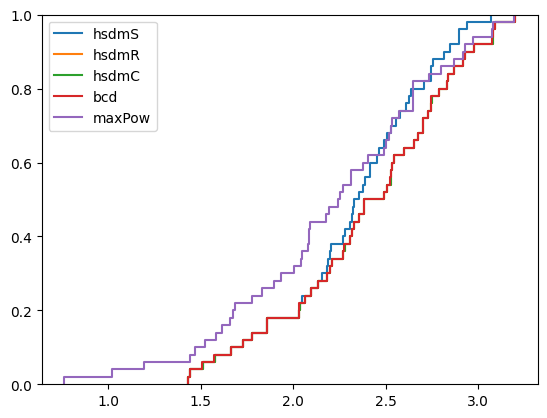

In [64]:
fig, ax = plt.subplots()
ax.ecdf(sumrate_hsdmS, label='hsdmS')
ax.ecdf(sumrate_hsdmR, label='hsdmR')
ax.ecdf(sumrate_hsdmC, label='hsdmC')
ax.ecdf(sumrate_bcd, label='bcd')
ax.ecdf(sumrate_maxPow, label='maxPow')

ax.legend()

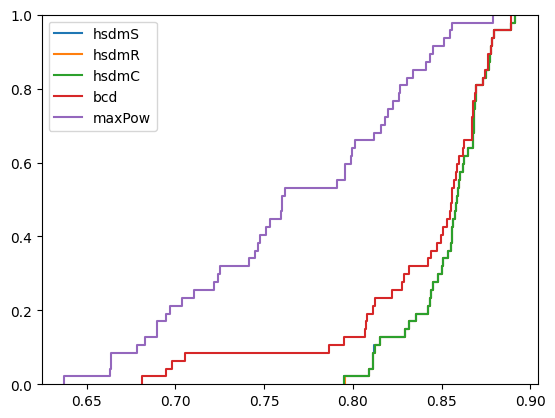

In [46]:
invZ_hsdmS = [sumrate for sumrate, inv in zip(sumrate_hsdmS, invZ) if  not inv]
invZ_hsdmR = [sumrate for sumrate, inv in zip(sumrate_hsdmR, invZ) if not inv]
invZ_hsdmC = [sumrate for sumrate, inv in zip(sumrate_hsdmC, invZ) if not inv]
invZ_bcd = [sumrate for sumrate, inv in zip(sumrate_bcd, invZ) if not inv]
invZ_maxPow = [sumrate for sumrate, inv in zip(sumrate_maxPow, invZ) if not inv]

fig, ax = plt.subplots()
ax.ecdf(invZ_hsdmS, label='hsdmS')
ax.ecdf(invZ_hsdmR, label='hsdmR')
ax.ecdf(invZ_hsdmC, label='hsdmC')
ax.ecdf(invZ_bcd, label='bcd')
ax.ecdf(invZ_maxPow, label='maxPow')

ax.legend()


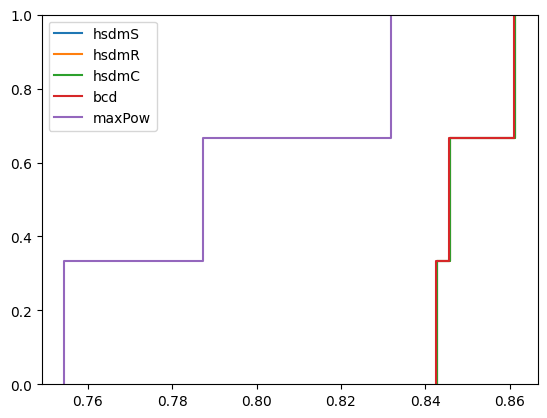

In [47]:
invZ_hsdmS = [sumrate for sumrate, inv in zip(sumrate_hsdmS, invZ) if inv]
invZ_hsdmR = [sumrate for sumrate, inv in zip(sumrate_hsdmR, invZ) if inv]
invZ_hsdmC = [sumrate for sumrate, inv in zip(sumrate_hsdmC, invZ) if inv]
invZ_bcd = [sumrate for sumrate, inv in zip(sumrate_bcd, invZ) if inv]
invZ_maxPow = [sumrate for sumrate, inv in zip(sumrate_maxPow, invZ) if inv]

fig, ax = plt.subplots()
ax.ecdf(invZ_hsdmS, label='hsdmS')
ax.ecdf(invZ_hsdmR, label='hsdmR')
ax.ecdf(invZ_hsdmC, label='hsdmC')
ax.ecdf(invZ_bcd, label='bcd')
ax.ecdf(invZ_maxPow, label='maxPow')

ax.legend()
